# 04 · Évaluation et démonstration de la vision

Une capture d'un **site jamais vu** devient la liste des éléments actionnables au format du
contrat de perception (JSON). On regarde ensuite **pourquoi** le détecteur décide (D-RISE), puis
**ce qu'il vaut** sur les tests figés, face à la baseline.

**Prérequis**

- `pip install -e '.[vision,capture]' jupyter`, puis `playwright install chromium`.
- `SBC_MODELS` : un dossier qui contient les fichiers de la release
  [`modeles-v1`](https://github.com/rayanmzr/SBC-Vision/releases/tag/modeles-v1).
- `SBC_REPORTS` : le dossier des rapports d'évaluation, produits par les commandes de
  `docs/VISION.md` (section « Reproduire »).

In [1]:
import hashlib
import io
import json
import os
import time
from pathlib import Path

import cv2
import numpy as np
from IPython.display import Image as Picture
from IPython.display import Markdown, display
from PIL import Image

from sbc_vision.contracts.perception import ImageSize, PerceptionResponse
from sbc_vision.perception.detector import load_detector
from sbc_vision.perception.elements import read_threshold, to_elements
from sbc_vision.perception.explain.drise import concentration, explain, overlay

MODELS = Path(os.environ["SBC_MODELS"])
REPORTS = Path(os.environ["SBC_REPORTS"])
SITE = "https://www.data.gouv.fr/fr/"  # absent du corpus WebUI et de nos tests
VIEWPORT = {"width": 1366, "height": 768}
MODEL = MODELS / "yolo26s-webui-1280-s0.onnx"

lines = (MODELS / "SHA256SUMS").read_text().splitlines()
sums = {name: digest for digest, name in (line.split() for line in lines)}
if hashlib.sha256(MODEL.read_bytes()).hexdigest() != sums[MODEL.name]:
    raise ValueError(f"{MODEL.name} ne correspond pas à SHA256SUMS de la release")


def show(image: np.ndarray, width: int = 1100) -> None:
    picture = Image.fromarray(image)
    picture.thumbnail((width, width))
    buffer = io.BytesIO()
    picture.save(buffer, format="JPEG", quality=85)
    display(Picture(data=buffer.getvalue(), format="jpeg"))


def zoom(image: np.ndarray, box: tuple[float, ...], margin: int = 160) -> np.ndarray:
    x1, y1, x2, y2 = (int(round(v)) for v in box)
    crop = image[max(y1 - margin, 0) : y2 + margin, max(x1 - margin, 0) : x2 + margin]
    return cv2.resize(crop, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)


def table(header: list[str], rows: list[list[str]]) -> None:
    lines = ["| " + " | ".join(header) + " |", "|" + " --- |" * len(header)]
    lines += ["| " + " | ".join(row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 1. Une capture d'un site jamais vu

La page telle qu'un visiteur la découvre, sur un écran d'ordinateur courant (1366 × 768),
bandeau de cookies compris.

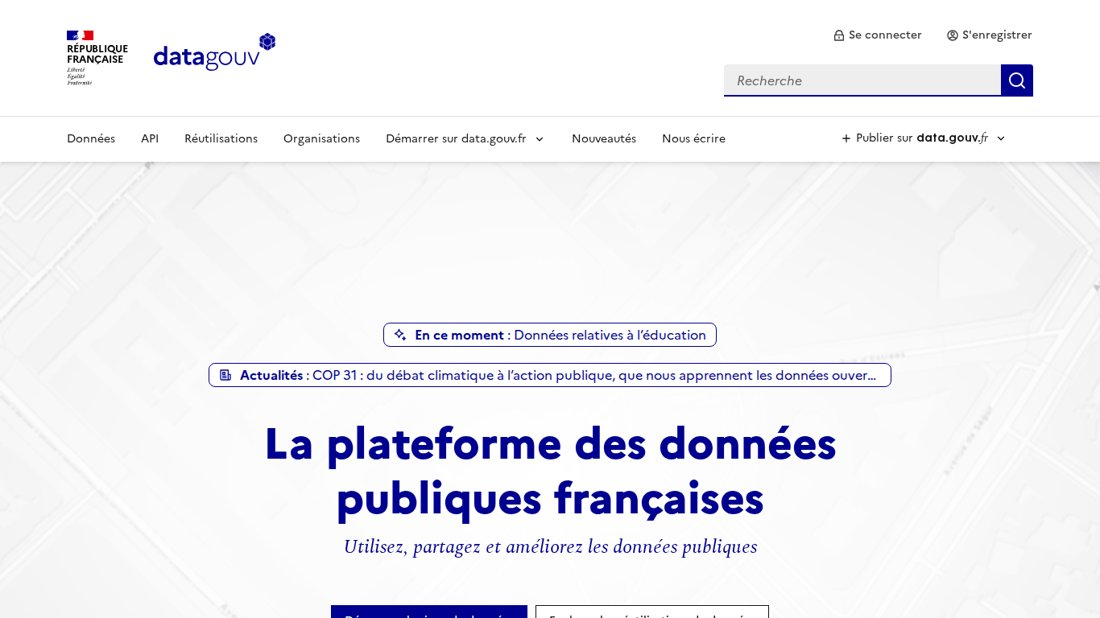

In [2]:
from playwright.async_api import async_playwright

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    page = await browser.new_page(viewport=VIEWPORT, locale="fr-FR")
    await page.goto(SITE, wait_until="load")
    await page.wait_for_timeout(3000)
    capture = np.asarray(Image.open(io.BytesIO(await page.screenshot())).convert("RGB"))
    await browser.close()

show(capture)

## 2. Ce que rend le détecteur

YOLO26s affiné sur 19 817 captures web, exécuté en ONNX sur processeur. Le seuil est celui du
meilleur F1 sur la validation : il n'est pas réglé sur cette page.

In [3]:
detector = load_detector(f"yolo:{MODEL}")
threshold = read_threshold(REPORTS / "yolo26s-webui-1280-s0/val/report.json")

started = time.perf_counter()
detections = detector.detect(capture)
latency_ms = (time.perf_counter() - started) * 1000

height, width = capture.shape[:2]
response = PerceptionResponse(
    capture_id="demo",
    image=ImageSize(width=width, height=height),
    model_name=detector.name,
    elements=to_elements(detections, threshold),
)
kinds = {}
for element in response.elements:
    kinds[element.kind.value] = kinds.get(element.kind.value, 0) + 1
print(f"{len(response.elements)} éléments au seuil {threshold:.2f} en {latency_ms:.0f} ms", kinds)
print(json.dumps(response.model_dump(mode="json")["elements"][:4], indent=2, ensure_ascii=False))

12 éléments au seuil 0.30 en 391 ms {'input': 1, 'button': 1, 'link': 10}
[
  {
    "id": "e0",
    "kind": "input",
    "bbox": {
      "x": 898,
      "y": 79,
      "width": 347,
      "height": 41
    },
    "text": null,
    "confidence": 0.9404922723770142,
    "actions": [
      "fill"
    ]
  },
  {
    "id": "e1",
    "kind": "button",
    "bbox": {
      "x": 1242,
      "y": 80,
      "width": 42,
      "height": 40
    },
    "text": null,
    "confidence": 0.8777745962142944,
    "actions": [
      "click"
    ]
  },
  {
    "id": "e2",
    "kind": "link",
    "bbox": {
      "x": 709,
      "y": 145,
      "width": 82,
      "height": 57
    },
    "text": null,
    "confidence": 0.8336046934127808,
    "actions": [
      "click"
    ]
  },
  {
    "id": "e3",
    "kind": "link",
    "bbox": {
      "x": 351,
      "y": 144,
      "width": 97,
      "height": 58
    },
    "text": null,
    "confidence": 0.8332342505455017,
    "actions": [
      "click"
    ]
  }
]


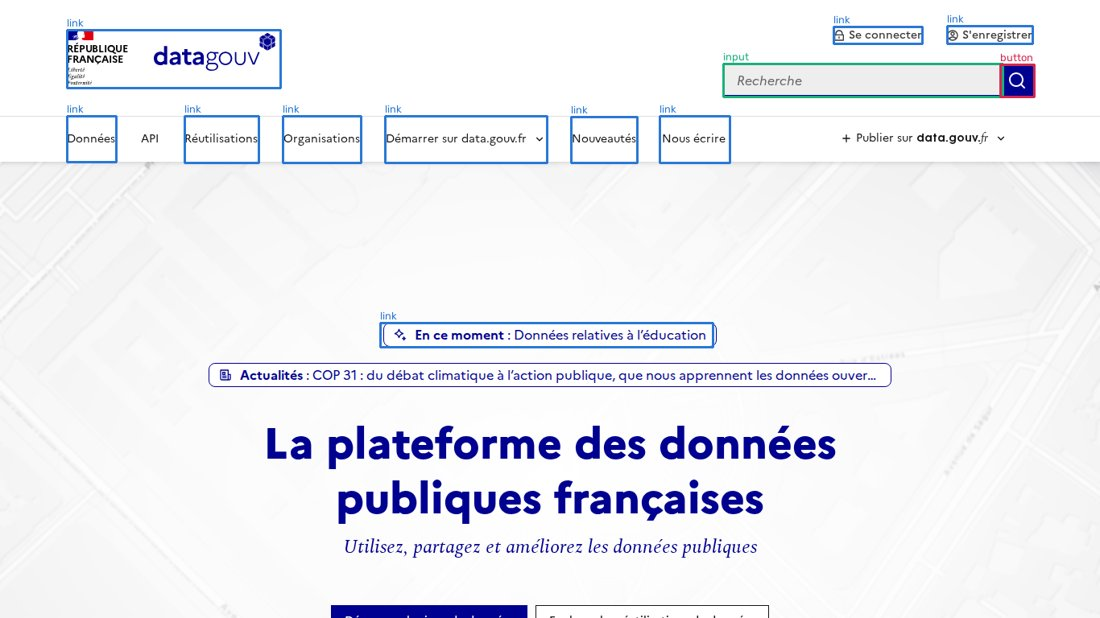

In [4]:
COLORS = {
    "button": (214, 39, 80),
    "link": (42, 120, 214),
    "input": (27, 175, 122),
    "menu": (237, 161, 0),
    "checkbox": (142, 68, 173),
}

drawn = capture.copy()
for element in response.elements:
    box, color = element.bbox, COLORS[element.kind.value]
    cv2.rectangle(drawn, (box.x, box.y), (box.x + box.width, box.y + box.height), color, 2)
    label = (box.x, max(box.y - 4, 10))
    cv2.putText(drawn, element.kind.value, label, cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)
show(drawn)

## 3. Pourquoi : D-RISE sur un bouton et un lien

On cache la page au hasard (1 000 masques, comme pour les mesures du rapport : quelques minutes
sur processeur) et on garde les masques qui laissent l'élément exister. En couleur : ce dont le
modèle a besoin pour le voir, en zoom autour de la boîte blanche. La concentration compare la
part de cette évidence dans la boîte à la part de l'image qu'elle occupe (×1 = pas plus
qu'ailleurs).

button 0.88 : concentration ×10


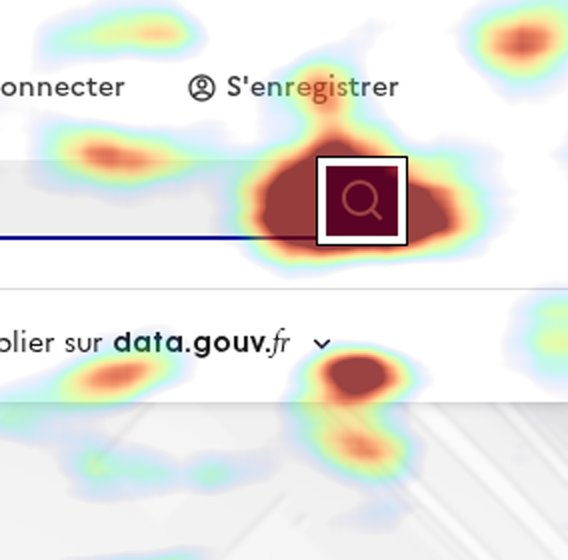

link 0.83 : concentration ×9


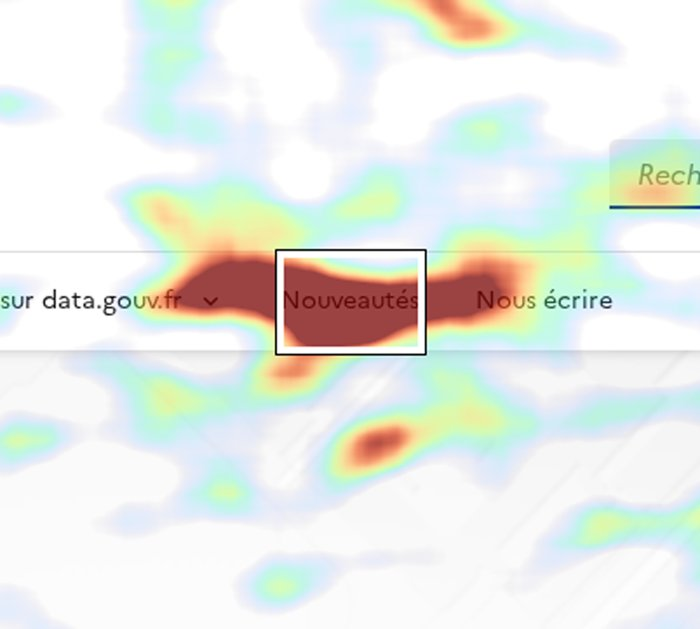

In [5]:
kept = [d for d in detections if d[2] >= threshold]
targets = [
    max((d for d in kept if d[0] == "button"), key=lambda d: d[2]),
    max((d for d in kept if d[0] == "link"), key=lambda d: d[2]),
]
saliency = explain(detector, capture, targets, count=1000)  # mêmes masques pour les deux
for (kind, box, score), heat in zip(targets, saliency, strict=True):
    print(f"{kind} {score:.2f} : concentration ×{concentration(heat, box):.0f}")
    show(zoom(overlay(capture, heat, box), box), width=700)

## 4. Les mesures

Mêmes sites, même outil (mAP à la manière de COCO, identique à `pycocotools`), seuil choisi sur
la validation et réutilisé tel quel. Intervalles à 95 % par rééchantillonnage des sites.

In [6]:
def report(model: str, split: str) -> dict:
    return json.loads((REPORTS / model / split / "report.json").read_text())


ROWS = [
    ("A · OpenCV + gradient boosting", "opencv-gbdt-v1"),
    ("B · YOLO26s", "yolo26s-webui-1280-s0"),
]
SPLITS = [
    ("validation, 500 sites", "val"),
    ("test, 1 000 sites", "test"),
    ("test vérifié, 48 captures de 5 sites", "ood"),
]
rows = []
for name, model in ROWS:
    for label, split in SPLITS:
        r = report(model, split)
        low, high = r["kind"]["mAP50_ci95"]
        rows.append(
            [
                name,
                label,
                f"{r['kind']['mAP50']:.3f} [{low:.2f} – {high:.2f}]",
                f"{r['action']['mAP50']:.3f}",
                f"{r['interactive']['mAP50']:.3f}",
                f"{r['kind']['operating_point']['_all']['f1']:.2f}",
                f"{r['latency_ms']['p50']:.0f} ms",
            ]
        )
header = [
    "Approche",
    "Jeu",
    "mAP@0,5 classe [IC 95 %]",
    "action",
    "interactif",
    "F1",
    "latence médiane",
]
table(header, rows)

| Approche | Jeu | mAP@0,5 classe [IC 95 %] | action | interactif | F1 | latence médiane |
| --- | --- | --- | --- | --- | --- | --- |
| A · OpenCV + gradient boosting | validation, 500 sites | 0.322 [0.28 – 0.37] | 0.330 | 0.336 | 0.39 | 150 ms |
| A · OpenCV + gradient boosting | test, 1 000 sites | 0.283 [0.23 – 0.34] | 0.299 | 0.335 | 0.38 | 166 ms |
| A · OpenCV + gradient boosting | test vérifié, 48 captures de 5 sites | 0.148 [0.08 – 0.25] | 0.201 | 0.239 | 0.23 | 367 ms |
| B · YOLO26s | validation, 500 sites | 0.605 [0.54 – 0.66] | 0.631 | 0.682 | 0.66 | 374 ms |
| B · YOLO26s | test, 1 000 sites | 0.539 [0.49 – 0.60] | 0.620 | 0.660 | 0.64 | 430 ms |
| B · YOLO26s | test vérifié, 48 captures de 5 sites | 0.340 [0.15 – 0.49] | 0.313 | 0.455 | 0.36 | 402 ms |

In [7]:
classes = ["input", "link", "checkbox", "button", "menu"]
a, b = report("opencv-gbdt-v1", "test"), report("yolo26s-webui-1280-s0", "test")
table(
    ["AP@0,5 sur le test", *classes],
    [[name, *(f"{r['kind']['AP50'][c]:.2f}" for c in classes)] for name, r in (("A", a), ("B", b))],
)

compare = REPORTS / "compare/yolo26s-webui-1280-s0-vs-opencv-test.json"
gap = json.loads(compare.read_text())["kind"]
low, high = gap["ci95"]
print(
    f"Écart apparié B − A sur le test : +{gap['mean_diff']:.2f} [{low:.2f} – {high:.2f}], "
    f"B ne fait pas mieux dans {gap['p_not_better']:.0%} des tirages"
)

| AP@0,5 sur le test | input | link | checkbox | button | menu |
| --- | --- | --- | --- | --- | --- |
| A | 0.56 | 0.31 | 0.37 | 0.17 | 0.01 |
| B | 0.87 | 0.63 | 0.46 | 0.39 | 0.34 |

Écart apparié B − A sur le test : +0.26 [0.22 – 0.30], B ne fait pas mieux dans 0% des tirages


## 5. Où se trompe-t-il ?

La matrice de confusion du test, au seuil de validation : pour chaque vraie classe, ce que le
détecteur en a fait.

In [8]:
confusion = b["confusion"]
names, matrix = confusion["classes"], np.array(confusion["matrix"])
rows = []
for i, name in enumerate(names[:-1]):
    total = matrix[i].sum()
    if total:
        rows.append([f"{name} ({total})", *(f"{share:.0%}" for share in matrix[i] / total)])
table(["vraie classe ↓ / prédite →", *names], rows)

missed = matrix[:-1, -1]
print(f"Manqués : {missed.sum()}, dont {missed[names.index('link')]} liens")
for size, recall in b["recall_by_size"].items():
    print(f"  {size} : {recall['recall']:.0%} trouvés sur {recall['count']}")

| vraie classe ↓ / prédite → | button | input | link | menu | checkbox | card | slot | background |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| button (1178) | 40% | 0% | 23% | 1% | 0% | 0% | 0% | 37% |
| input (476) | 1% | 84% | 3% | 1% | 0% | 0% | 0% | 12% |
| link (13723) | 1% | 0% | 63% | 0% | 0% | 0% | 0% | 36% |
| menu (151) | 5% | 4% | 24% | 36% | 0% | 0% | 0% | 31% |
| checkbox (77) | 1% | 0% | 4% | 0% | 53% | 0% | 0% | 42% |

Manqués : 5522, dont 4955 liens
  small : 54% trouvés sur 2908
  medium : 68% trouvés sur 10215
  large : 63% trouvés sur 2482


**À retenir**

- Un bouton pris pour un **lien** reste une action juste (un clic) : c'est pourquoi le score au
  niveau action dépasse celui au niveau classe. D-RISE et le corpus l'expliquent : dans WebUI,
  91 % des éléments au gabarit d'un bouton sont codés comme des liens (`docs/VISION.md`,
  « Explicabilité »).
- La colonne « background » d'une vraie classe, ce sont les éléments **manqués** : neuf sur
  dix sont des liens (ce sont aussi les plus nombreux), et les petits éléments sont les moins
  bien trouvés.
- Sur le test vérifié à la main, un widget absent de l'entraînement (le calendrier ouvert
  d'Airbnb) suffit à faire tomber un site : c'est ce que l'adaptation à la Web App doit couvrir.